# Lab 3: Working with Climate Data
Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only

Name = " "

***Note:*** The functions/code provided are one of many ways that can work. Feel free to use functions you are more familiar with!\
***Figures:*** For any figures, label axis and title clearly for full points. 

## Lab Objectives:

1.	Understand Drought indicators: Identify and describe the differences between various drought indices such as CMI, PDSI, and SPI.
2.	Calculate and interpret mean, median, mode, and standard deviation.
3.	Quantify and describe relationships between various drought and temperature indices using scatter plots and correlation coefficients.
  
## Lab Activities: 
This assignment has three parts. Make sure you complete all of them. Parts A, B, and C are worth 10, 20, and 30 points for 60 total points. Detailed instructions for each part can be found in the subsections below.

In [1]:
import pandas as pd #data frame
import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import math
import seaborn as sns


### Introduction to Climate Variables
In this lab, we will use time series datasets from NOAA's National Climate Data Center, which includes several climate indicators such as:
- Precipitation (inches)
- Temperature (degrees Fahrenheit)
- Cooling Degree Days (CDD)
- Heating degree days (HDD)
- Palmer drought indices
    - Palmer Z Index (ZNDX)
    - Palmer Drought Severity Index (PDSI)
    - Palmer Modified Drought Index (PMDI)
    - Palmer Hydrological Drought Index (PHDI)
      
Read more about these indices from the following webpages:
- [Cooling and Heating Degree Days](https://www.cpc.ncep.noaa.gov/pacdir/DDdir/INT1.html)
- [Historical Palmer Drought Indices](https://www.ncei.noaa.gov/access/monitoring/historical-palmers/overview)
-	Heim, Jr., Richard R., 2002: A review of Twentieth-Century drought indices used in the United States. Bulletin of the American Meteorological Society, vol. 83, pp. 1149- 1165. (Paper attached in the lab assginment for download, this is needed for your lab 3)


Part 3A (10 points). Palmer drough indices and other climate variables from the .txt files
- 	Data files: You should now have three text files with data: South Region, Texas State, and Central Division (Brazos Valley). You can open them in a txt editor to examine them.
-  The columns represent various climate data such as precipitation (PCP), temperature (TMP), Palmer drought indices (PDSI, PHDI, ZNDX, PMDI), cooling/heating degree days (CDD, HDD), and several standardized precipitation indices (SP01, SP02, SP03, etc.).

1.	In your own words, describe the CMI (Crop Moisture Index) and PDSI (Palmer Drought severity Index), how they are determined, and how they differ. Use the provided review paper by Heim and Richard (2002) for reference. \
Enter your answer here: 





Part 3B (20 points). Importing and plotting data
1. Use the pd.read_csv() function to import and save all three datasets; 
2. Use df.head() to examine first few rows of data

3. Plot the PDSI (6th column) over time for all three datasets in a same plot. Use distinct colors or symbols for each dataset and include a legend. Label x and y axis accordingly. Make sure the x-axis is on the correct time units (convert to date time format)

In [3]:
#your code to read and check the data
#df_tx = pd.read_csv('texas_2006_2015.txt', sep='\s+')
#df_st = pd.read_csv('south_2006_2015.txt', sep='\s+')
#df_sc = pd.read_csv('southcentraltexas_2006_2015.txt', sep='\s+')
df_tx = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/texas_2006_2015-1.txt', sep=r'\s+')
df_st = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/south_2006_2015-2.txt', sep=r'\s+')
df_sc = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/southcentraltexas_2006_2015.txt', sep=r'\s+')
df_tx.head(10)

,StateCode,Division,YearMonth,PCP,TAVG,PDSI,PHDI,ZNDX,PMDI,CDD,HDD,SP01,SP02,SP03,SP06,SP09,SP12,SP24,TMIN,TMAX
0,41,0,200601,1.06,52.9,-3.21,-3.21,-2.54,-3.21,38,328,-0.43,-1.37,-1.52,-1.11,-1.21,-1.16,0.81,37.5,68.3
1,41,0,200602,1.14,50.3,-3.56,-3.56,-2.03,-3.56,13,369,-0.46,-0.61,-1.27,-1.62,-1.26,-1.46,0.62,36.3,64.2
2,41,0,200603,2.07,61.1,-3.43,-3.43,-0.72,-3.43,103,147,0.48,-0.01,-0.24,-0.94,-0.79,-1.39,0.60,48.7,73.5
3,41,0,200604,1.51,70.7,-4.11,-4.11,-3.10,-4.11,231,14,-0.59,-0.09,-0.33,-1.16,-1.11,-1.24,0.29,57.0,84.4
4,41,0,200605,2.20,75.7,-4.96,-4.96,-3.81,-4.96,349,0,-0.82,-1.07,-0.63,-1.21,-1.54,-1.36,0.28,62.2,89.3
5,41,0,200606,1.96,80.8,-5.57,-5.57,-3.37,-5.57,475,0,-0.66,-1.06,-1.23,-1.00,-1.29,-1.18,-0.39,67.6,93.9
6,41,0,200607,2.31,83.4,-5.60,-5.60,-1.80,-5.60,579,0,0.03,-0.53,-0.94,-0.88,-1.35,-1.25,-0.39,71.4,95.4
7,41,0,200608,2.36,83.6,-5.29,-5.29,-0.80,-5.29,627,0,0.22,0.01,-0.46,-0.73,-1.12,-1.41,-0.50,71.7,95.3
8,41,0,200609,3.27,74.1,0.14,-4.60,0.41,-4.40,348,4,0.34,0.28,0.13,-0.74,-0.71,-1.05,-0.45,61.9,86.2
9,41,0,200610,4.03,66.8,0.69,-3.56,1.71,-2.66,173,44,0.98,0.86,0.75,-0.07,-0.22,-0.73,-0.46,54.3,79.3


/tmp/ipykernel_12726/1622604662.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


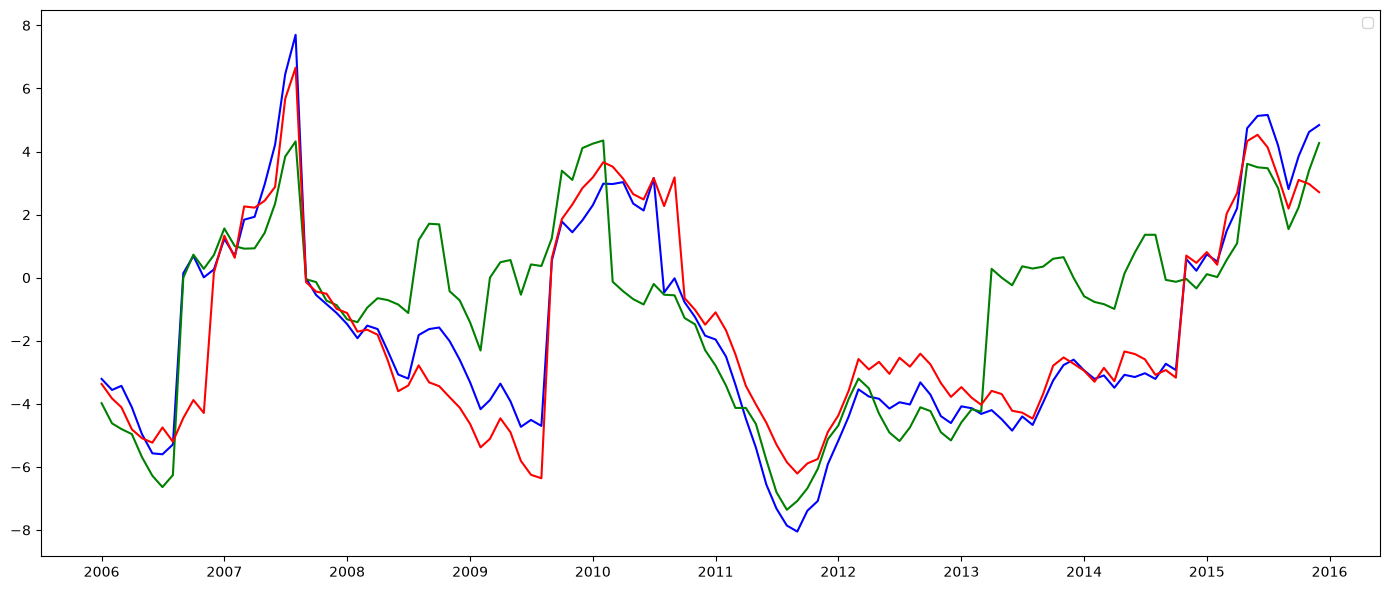

In [ ]:
#your code to plot
df_tx['Date'] = pd.to_datetime(df_tx['YearMonth'], format='%Y%m')
df_st['Date'] = pd.to_datetime(df_st['YearMonth'], format='%Y%m')
df_sc['Date'] = pd.to_datetime(df_sc['YearMonth'], format='%Y%m')

#create canvas, specify canvas size
plt.figure(figsize=(14, 6))

#Practise fill in the code to plot PDSI over for Texas, label and color it
sns.lineplot(x = 'Date', y='PDSI', data=df_tx, label='Texas', color='b')
sns.lineplot(x = 'Date', y='PDSI', data=df_st, label='South', color='g')
sns.lineplot(x = 'Date', y='PDSI', data=df_sc, label='South Central', color='r')
plt.xlabel('')
plt.ylabel('')
plt.title('')
plt.legend()

#show the data
plt.tight_layout()
plt.show()

Part 3C (30 points):Descriptive statistics, correlation, and data analysis
1. Calculate descriptive statistics
For each dataset (South Region, Texas State, southcentral Division), calculate the standard deviation, mean, mode, and median for PDSI, temperature (TMP), and precipitation (PCP).

In [2]:
#Your code to calculate the statistics

#make sure to use print() to display the results
#e.g., print("Mean PDSI for South Region:", mean_pdsi_south)
#or you can write your results in a markdown cell



2. Plot histograms:
plot three histograms of PDSI (one subplot for each dataset) with three rows and 1 column using the subplot() command. Add vertical lines representing each plot's mean, median, mode, and ± standard deviation. Follow the template in our class demo.

In [19]:
#your code for plotting




3. Describe the plot: Assess the drought severity during the selected period for each region based on the histogram plots.\
Type your answer here:

4. Create scatter plot to compare the South region's PDSI with the Texas State PDSI, and compare the PDSI of South region vs that of south central region. So here both x and y will be PDSI. But we would have two clusters. Make sure to color them differently and provide legend for the color. Label the axes appropriately.


In [20]:
#your code to plot



In [ ]:
#your code for plotting

6. Correlation coefficients: compute the correlation coefficients between PDSI values from different regions. (south vs texas, south vs south central, texas vs south central)


In [16]:
#your code to calculate the correlation coefficients; use the pearsonr function
#make sure to use print() to display the results 
#or write your results in a markdown cell or comment


Correlation coefficient (South vs Texas PDSI): 0.785
Correlation coefficient (South vs Central PDSI): 0.352
Pearson correlation (South vs Texas): 0.785 (p=2.795e-26)
Pearson correlation (South vs Central): 0.352 (p=7.951e-05)


Explain the different correlation coeffcients in the context of the scatter plots you generated, focusing on the relationships between different regions.
Type your answer here:

7. Plot CDD vs HDD: Plot Cooling Degree Days (CDD) versus Heating Degree Days (HDD) for the Texas dataset and assess whether the relationship is linear. 

In [1]:
#your code to plot 


In [2]:
#your code to calculate the correlation coefficients


8. Correlation analysis:
Calculate the correlation coefficients between PDSI and PCP, PDSI and PHDI, and PDSI and ZNDX for Texas and the south entral Region.

In [3]:
#your code to calculate the correlation coefficients
#make sure to use print() to display the results

Describe the results: Highlight which variables are correlated and discuss their implications.